# T25. Líneas base de localización

**Objetivo.** Comparar K-medoids ponderado y K-means ponderado ajustado a candidatos de T24 para varios presupuestos de estaciones y radios de acceso.

**Valor para el proyecto.** Establecer dos referencias que los modelos de cobertura y p-mediana tendrán que mejorar. Se evalúan con los extremos geográficos originales del ajuste. La selección y validación de la red queda para T28 y T30.

In [1]:
import math

import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import linear_sum_assignment
from scipy.spatial import cKDTree
from scipy.spatial.distance import cdist

from comun.config import cargar_config, carpeta_tablas, ruta
from comun.datos import cargar_viajes
from comun.figuras import guardar_figura, plt
from comun.geo import haversine_m
from comun.web import exportar

TEMA = "movilidad"
TABLAS = carpeta_tablas(TEMA)
cfg = cargar_config()
radios = cfg["movilidad"]["radios_acceso_m"]
semilla = cfg["semilla"]
REINICIOS = 3
MAX_ITERACIONES = 80
PASO_K = 10
OBJETIVO_COBERTURA_PCT = 80
METODOS = {"kmedoids": "K-medoids", "kmeans": "K-means a candidatos"}

catalogo = pd.read_csv(TABLAS / "T24_candidatos.csv", dtype={"candidate_id": str})
viajes = cargar_viajes(periodo="ajuste")
xy = catalogo[["x_m", "y_m"]].to_numpy()
pesos = catalogo["extremos"].to_numpy(dtype=float)
incluido = catalogo["incluido_barrido"].to_numpy()
permitidos = np.flatnonzero(incluido)
lat, lon = catalogo["lat"].to_numpy(), catalogo["lon"].to_numpy()
d_geodesica = haversine_m(lat[:, None], lon[:, None], lat[None, :], lon[None, :])
assert catalogo["candidate_id"].is_unique and (pesos > 0).all() and pesos.sum() == 2 * len(viajes)
assert len(np.unique(xy, axis=0)) == len(xy)

## 1. Presupuestos y métodos

**Qué queremos ver.** Cómo cambia la red al variar `k`. Para cada radio usamos el rango de T13 del 80 al 95 % de los extremos, ampliado un 20 % por cada lado. Probamos los extremos del intervalo, los tres tamaños orientativos de T13 y múltiplos de 10.

**Por qué importa.** Las dos referencias parten de los mismos pesos y posiciones. K-means aproxima las celdas en UTM y se lleva a candidatos únicos mediante una asignación de coste mínimo. K-medoids minimiza la distancia geográfica ponderada en cada grupo y mantiene los centros dentro del catálogo.

In [2]:
orden = pd.read_csv(ruta("tablas") / "exploracion" / "T13_estaciones_orden_magnitud.csv")
anclas = orden.loc[orden["cuota_pct"].isin([80, 90, 95])].pivot(
    index="radio_m", columns="cuota_pct", values="estaciones_orden_magnitud"
)
ks_por_radio, referencia = {}, {}
for radio in radios:
    a, b, c = (int(anclas.loc[radio, cuota]) for cuota in (80, 90, 95))
    k_min = max(1, math.floor(.8 * a))
    k_max = min(len(permitidos), math.ceil(1.2 * c))
    cifras = {k_min, k_max, a, b, c, *range(math.ceil(k_min / PASO_K) * PASO_K, k_max + 1, PASO_K)}
    ks_por_radio[radio] = sorted(k for k in cifras if k_min <= k <= k_max)
    if not ks_por_radio[radio]:
        raise ValueError(f"No hay suficientes candidatos para el barrido de {radio} m.")
    referencia[radio] = min(ks_por_radio[radio], key=lambda k: abs(k - b))
todos_k = sorted(set().union(*ks_por_radio.values()))
display(pd.DataFrame([{"radio_m": radio, "k_min": ks[0], "k_max": ks[-1],
                       "k_referencia": referencia[radio], "n_presupuestos": len(ks)}
                      for radio, ks in ks_por_radio.items()]))

,radio_m,k_min,k_max,k_referencia,n_presupuestos
0,200,184,465,317,32
1,250,117,298,203,23
2,300,81,207,141,17
3,400,46,117,80,11


In [3]:
def semillas_ponderadas(k, rng):
    """Inicialización k-means++ con probabilidad proporcional a peso por distancia al cuadrado."""
    primero = rng.choice(permitidos, p=pesos[permitidos] / pesos[permitidos].sum())
    elegidos = [primero]
    cercania = np.full(len(permitidos), np.inf)
    for _ in range(1, k):
        ultimo = xy[elegidos[-1]]
        cercania = np.minimum(cercania, np.sum((xy[permitidos] - ultimo) ** 2, axis=1))
        importancia = pesos[permitidos] * cercania
        elegidos.append(rng.choice(permitidos, p=importancia / importancia.sum()))
    return np.array(elegidos)


def kmeans(inicio):
    centros = xy[inicio].copy()
    k = len(centros)
    for paso in range(1, MAX_ITERACIONES + 1):
        d2 = cdist(xy, centros, metric="sqeuclidean")
        grupo = d2.argmin(axis=1)
        masa = np.bincount(grupo, weights=pesos, minlength=k)
        llenos = masa > 0
        nuevos = np.empty_like(centros)
        for eje in range(2):
            suma = np.bincount(grupo, weights=pesos * xy[:, eje], minlength=k)
            nuevos[llenos, eje] = suma[llenos] / masa[llenos]
        if not llenos.all():
            error = pesos * d2[np.arange(len(xy)), grupo]
            peores = np.argsort(-error[permitidos], kind="stable")[:int((~llenos).sum())]
            nuevos[~llenos] = xy[permitidos[peores]]
        if np.allclose(nuevos, centros, rtol=0, atol=1e-6):
            centros = nuevos
            break
        centros = nuevos

    # Asignación uno a uno. Dos centroides pueden tener el mismo candidato más próximo.
    _, columnas = linear_sum_assignment(cdist(centros, xy[permitidos], metric="sqeuclidean"))
    red = np.sort(permitidos[columnas])
    sse = pesos @ cdist(xy, xy[red], metric="sqeuclidean").min(axis=1)
    return float(sse), red, paso


def kmedoids(inicio):
    red = np.sort(inicio)
    for paso in range(1, MAX_ITERACIONES + 1):
        grupos = d_geodesica[:, red].argmin(axis=1)
        nuevos = []
        for j in range(len(red)):
            miembros = np.flatnonzero(grupos == j)
            admisibles = miembros[incluido[miembros]]
            costes = pesos[miembros] @ d_geodesica[np.ix_(miembros, admisibles)]
            nuevos.append(admisibles[costes.argmin()])
        nuevos = np.sort(nuevos)
        if np.array_equal(red, nuevos):
            break
        red = nuevos
    coste = pesos @ d_geodesica[:, red].min(axis=1)
    return float(coste), red, paso


def resolver(k):
    inicios = [semillas_ponderadas(k, np.random.default_rng(np.random.SeedSequence([semilla, k, i])))
               for i in range(REINICIOS)]
    ajuste_means = min(map(kmeans, inicios), key=lambda resultado: resultado[0])
    # Se añade la red de K-means como inicio para comparar también desde esa solución.
    ajuste_medoids = min(map(kmedoids, [*inicios, ajuste_means[1]]), key=lambda resultado: resultado[0])
    return {"kmedoids": ajuste_medoids[1:], "kmeans": ajuste_means[1:]}

redes = {k: resolver(k) for k in todos_k}
assert all(len(indices) == len(np.unique(indices)) == k
           for k, alternativas in redes.items() for indices, _ in alternativas.values())

**Conclusiones.** El ajuste al catálogo conserva el número de estaciones solicitado. La semilla, el orden de los candidatos y los reinicios hacen reproducible la comparación. Los dos métodos son heurísticos y su objetivo de ajuste usa celdas ponderadas.

## 2. Cobertura y acceso en los viajes

**Qué queremos ver.** Qué parte de los viajes del ajuste tiene una estación a la distancia requerida en los dos extremos. También se miden origen y destino por separado y las distancias mediana y P90 sobre todos los extremos.

**Por qué importa.** El coste de ajustar celdas no refleja por sí solo el acceso de los viajes reales. La cobertura completa conserva el emparejamiento origen–destino y usa distancias de círculo máximo. El 80 % es una cota de comparación compartida con T36.

In [4]:
def esfera(latitud, longitud):
    phi, lam = np.radians(latitud), np.radians(longitud)
    return np.column_stack((np.cos(phi) * np.cos(lam), np.cos(phi) * np.sin(lam), np.sin(phi)))


lat_ext = np.r_[viajes["latO"], viajes["latD"]]
lon_ext = np.r_[viajes["lonO"], viajes["lonD"]]
esfera_ext = esfera(lat_ext, lon_ext)
esfera_cand = esfera(lat, lon)
alertas = (catalogo["alerta_rio"] | catalogo["alerta_via"] | ~catalogo["recorte_osm"]).to_numpy()
n = len(viajes)
filas, catalogos = [], []
for k, alternativas in redes.items():
    for metodo, (indices, iteraciones) in alternativas.items():
        red_id = f"{metodo}_k{k}"
        _, cercanos = cKDTree(esfera_cand[indices]).query(esfera_ext)
        asignados = indices[cercanos]
        distancia = haversine_m(lat_ext, lon_ext, lat[asignados], lon[asignados])
        origen, destino = distancia[:n], distancia[n:]
        base = {
            "network_id": red_id, "metodo": metodo, "k": k, "estaciones_distintas": len(indices),
            "estaciones_con_avisos": int(alertas[indices].sum()), "viajes_ajuste": n,
            "iteraciones": iteraciones, "d_media_m": distancia.mean(), "d_p90_m": np.quantile(distancia, .9),
        }
        for nombre, d in (("origen", origen), ("destino", destino)):
            base[f"d_{nombre}_media_m"] = d.mean()
            base[f"d_{nombre}_mediana_m"] = np.median(d)
            base[f"d_{nombre}_p90_m"] = np.quantile(d, .9)
        for radio in radios:
            if k not in ks_por_radio[radio]:
                continue
            o, d = origen <= radio, destino <= radio
            ambos = o & d
            filas.append({
                **base, "radio_m": radio, "viajes_cubiertos": int(ambos.sum()),
                "viajes_un_extremo": int((o ^ d).sum()), "viajes_sin_cobertura": int((~o & ~d).sum()),
                "pct_viajes_cubiertos": 100 * ambos.mean(),
                "pct_origenes_cubiertos": 100 * o.mean(), "pct_destinos_cubiertos": 100 * d.mean(),
                "pct_extremos_cubiertos": 50 * (o.mean() + d.mean()),
            })
        estaciones = (catalogo.iloc[indices][["candidate_id", "lat", "lon", "extremos"]]
                      .rename(columns={"candidate_id": "station_id", "extremos": "extremos_celda_ajuste"}))
        catalogos.append(estaciones.assign(network_id=red_id, metodo=metodo, k=k,
                                         aviso_cartografico=alertas[indices]))

barrido = pd.DataFrame(filas).sort_values(["radio_m", "metodo", "k"]).reset_index(drop=True)
cat_redes = pd.concat(catalogos, ignore_index=True)
cat_redes = cat_redes[["network_id", "metodo", "k", "station_id", "lat", "lon",
                     "extremos_celda_ajuste", "aviso_cartografico"]]
assert (barrido["viajes_cubiertos"] + barrido["viajes_un_extremo"] + barrido["viajes_sin_cobertura"]).eq(n).all()

resumenes = []
for (radio, metodo), grupo in barrido.groupby(["radio_m", "metodo"]):
    ref = grupo.loc[grupo["k"].eq(referencia[radio])].iloc[0]
    alcanza = grupo.loc[grupo["pct_viajes_cubiertos"].ge(OBJETIVO_COBERTURA_PCT)]
    resumenes.append({
        "radio_m": radio, "metodo": metodo, "k_min": grupo["k"].min(), "k_max": grupo["k"].max(),
        "presupuestos": len(grupo), "k_min_80_pct": int(alcanza["k"].min()) if len(alcanza) else None,
        "k_referencia": int(ref["k"]), "pct_viajes_cubiertos_ref": ref["pct_viajes_cubiertos"],
        "d_media_ref_m": ref["d_media_m"], "d_p90_ref_m": ref["d_p90_m"],
    })
resumen = pd.DataFrame(resumenes).round(4)
barrido = barrido.round(4)
barrido.to_csv(TABLAS / "T25_barrido.csv", index=False, lineterminator="\n")
cat_redes.to_csv(TABLAS / "T25_redes.csv", index=False, float_format="%.9f", lineterminator="\n")
resumen.to_csv(TABLAS / "T25_resumen.csv", index=False, lineterminator="\n")
display(resumen)

,radio_m,metodo,k_min,k_max,presupuestos,k_min_80_pct,k_referencia,pct_viajes_cubiertos_ref,d_media_ref_m,d_p90_ref_m
0,200,kmeans,184,465,32,350.0,317,73.6266,146.0791,230.5302
1,200,kmedoids,184,465,32,350.0,317,74.6499,145.6666,229.0840
2,250,kmeans,117,298,23,280.0,203,64.2250,179.1748,316.8151
3,250,kmedoids,117,298,23,280.0,203,63.7822,180.6748,327.4801
4,300,kmeans,81,207,17,NaN,141,58.4022,220.8166,388.8541
5,300,kmedoids,81,207,17,NaN,141,58.6176,219.0718,389.2824
6,400,kmeans,46,117,11,NaN,80,58.0790,296.7275,478.5603
7,400,kmedoids,46,117,11,NaN,80,60.2873,288.6428,486.1092


**Conclusiones.** El primer presupuesto que alcanza el 80 % se refiere a los tamaños ensayados. Las redes de tamaños distintos se optimizan por separado y pueden cambiar de estación al aumentar `k`. Las distancias son geométricas y se contrastarán con rutas a pie en T29.

## 3. Curvas de cobertura y catálogos de red

**Qué queremos ver.** Para cada radio, cuántos viajes se cubren con cada presupuesto y qué estaciones forman las dos redes.

**Por qué importa.** Los catálogos y métricas se pueden reutilizar al comparar T26–T28. Los tamaños de referencia son los de la cuota del 90 % de T13 y se fijan antes de calcular la cobertura.

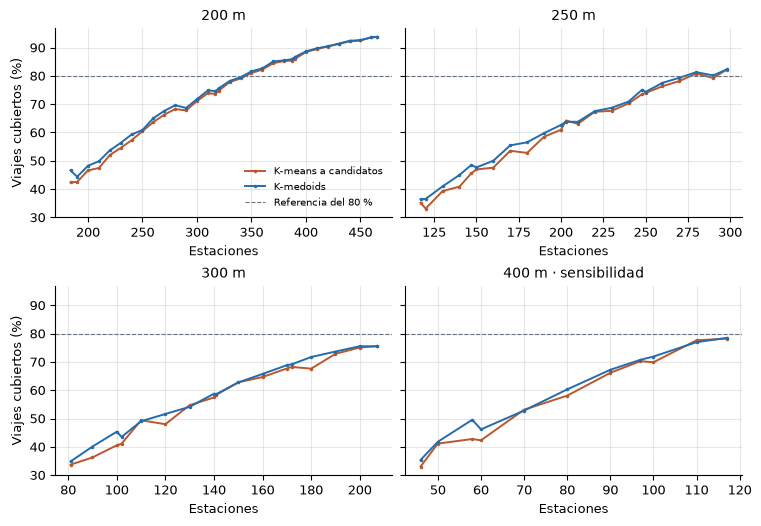

In [5]:
fig, ejes = plt.subplots(math.ceil(len(radios) / 2), 2, figsize=(7.5, 5.15), squeeze=False,
                         sharey=True, layout="constrained")
colores = {"kmedoids": "#246cab", "kmeans": "#bc572d"}
for posicion, (eje, radio) in enumerate(zip(ejes.flat, radios)):
    for metodo, grupo in barrido.loc[barrido["radio_m"].eq(radio)].groupby("metodo"):
        eje.plot(grupo["k"], grupo["pct_viajes_cubiertos"], marker=".", markersize=3, lw=1.4,
                 label=METODOS[metodo], color=colores[metodo])
    eje.axhline(OBJETIVO_COBERTURA_PCT, color="#677382", ls="--", lw=0.8, label="Referencia del 80 %")
    titulo = f"{radio} m" if radio != max(radios) else f"{radio} m · sensibilidad"
    eje.set(title=titulo, xlabel="Estaciones", ylabel="Viajes cubiertos (%)" if posicion % 2 == 0 else "")
for eje in list(ejes.flat)[len(radios):]:
    eje.set_visible(False)
ejes[0, 0].legend(frameon=False, loc="lower right", fontsize=7.5)
guardar_figura(fig, TEMA, "T25_cobertura")

catalogo_web = (catalogo[["candidate_id", "x_m", "y_m"]]
                .assign(x_km=(catalogo["x_m"] / 1_000).round(4), y_km=(catalogo["y_m"] / 1_000).round(4))
                .drop(columns=["x_m", "y_m"]))
exportar("fase1", "t25_lineas_base", {
    "radios": radios, "referencias": referencia, "objetivo_pct": OBJETIVO_COBERTURA_PCT,
    "metodos": METODOS, "barrido": barrido, "resumen": resumen, "candidatos": catalogo_web,
    "redes": {f"{metodo}_k{k}": indices for k, alternativas in redes.items()
             for metodo, (indices, _) in alternativas.items()},
})

**Conclusiones.** Las redes fijan una referencia de acceso y cobertura con el mismo conjunto de viajes y candidatos. T26 y T27 podrán probar objetivos de cobertura de viajes completos. La evaluación con la semana reservada se hará con las redes congeladas.